## Création fichier étalonnage des thermocouples

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import h5py
import pandas as pd
import datetime
import os
import scipy as sc
import json

ModuleNotFoundError: No module named 'matplotlib'

# Importation des données

In [46]:
def h5_to_df(data) : # Chargement des données h5 dans un DataFrames
    dict_data = {}
    for (mesure,voie,start,stop) in data :
        if mesure == "Température" :
            if stop == -1 :
                TC = File['RawData']['Scan000']['Detector000']['Data0D']['CH00']['EnlData'+str(voie)][start:]
            elif start == 0 :
                TC = File['RawData']['Scan000']['Detector000']['Data0D']['CH00']['EnlData'+str(voie)][:stop]
            else :
                TC = File['RawData']['Scan000']['Detector000']['Data0D']['CH00']['EnlData'+str(voie)][start:stop]
            dict_data["CH"+str(voie)] = [TC[i][0] for i in range(len(TC))]
            continue
        elif mesure == "Pression" :
            if stop == -1 :
                P = File['RawData']['Scan000']['Detector000']['Data0D']['CH01']['EnlData'+str(voie)][start:]
            elif start == 0 :
                P = File['RawData']['Scan000']['Detector000']['Data0D']['CH01']['EnlData'+str(voie)][:stop]
            else :
                P = File['RawData']['Scan000']['Detector000']['Data0D']['CH01']['EnlData'+str(voie)][start:stop]
            dict_data[mesure] = [(P[i][0]-0.0253)/4.9731 for i in range(len(P))]
            continue
        elif mesure == "Voltage" :
            if stop == -1 :
                U = File['RawData']['Scan000']['Detector000']['Data0D']['CH01']['EnlData'+str(voie)][start:]
            elif start == 0 :
                U = File['RawData']['Scan000']['Detector000']['Data0D']['CH01']['EnlData'+str(voie)][:stop]
            else :
                U = File['RawData']['Scan000']['Detector000']['Data0D']['CH01']['EnlData'+str(voie)][start:stop]
            dict_data[mesure] = [U[i][0] for i in range(len(U))]
            continue
        elif mesure == "time" :
            if stop == -1 :
                t = File['RawData']['Scan000']['Detector000']['NavAxes']['Axis00'][start:]
            elif start == 0 :
                t = File['RawData']['Scan000']['Detector000']['NavAxes']['Axis00'][:stop]
            else :
                t = File['RawData']['Scan000']['Detector000']['NavAxes']['Axis00'][start:stop]
            dict_data["Date"] = [datetime.datetime.fromtimestamp(i) for i in t]
            dict_data["Temps"] = list(t-t[0])
            continue
        
    df = pd.DataFrame(dict_data)
        
    return  df

In [47]:
path = r"C:\Users\yseyve\Documents\CETHIL\Caprep\Etude_des_bouchons\Resultats_expe\Resultat_etancheite_ok\Etalonnage\TC\Etalonnage_1\examples\Scan_20260113_17_57_54.h5"
plateau = [10,30,50,70,90,110,130,150] ## Température d'étalonnage

## Importation données brut
File = h5py.File(path,'r')

## Choix des données traitées
start = 0
stop = -1

## Création dictionnaire des variables à récupérer
data_in = [("time","02",start,stop),("Voltage","00",start,stop),\
           ("Voltage","01",start,stop),("Pression","02",start,stop),\
           ("Température","01",start,stop),("Température","02",start,stop),\
           ("Température","03",start,stop),("Température","04",start,stop),\
           ("Température","05",start,stop),\
           ("Température","07",start,stop),("Température","08",start,stop),\
           ("Température","09",start,stop),("Température","10",start,stop)]

df_data= h5_to_df(data_in)


## Préparation données de l'étalonnage

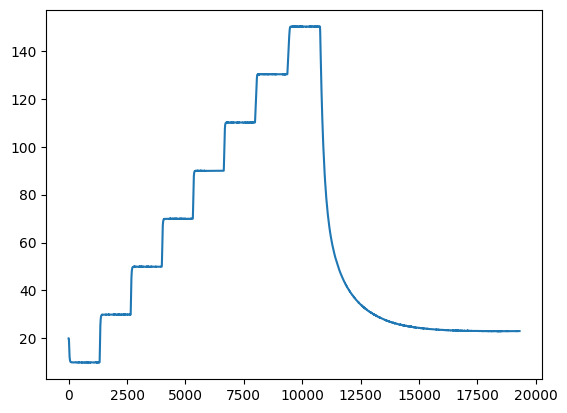

In [48]:
plt.plot(df_data["CH01"])

In [49]:
def delete_usless_data(data) :

    # Find minimum and maximum value and save there index
    ind_min = list(data).index(np.min(data))
    ind_max = list(data).index(np.max(data))

    # Cut data end keep only value between maximum and minumum
    data_use = data[ind_min:ind_max]

    data_use.reset_index(inplace = True,drop=True)

    return data_use

def copy_and_delete_from_series(series: pd.Series, start_index: int, end_index: int) -> pd.Series:
    """
    Copie et supprime une plage d'index d'une Series pandas.

    Args:
        series: La Series pandas d'origine.
        start_index: Index de début (inclus).
        end_index: Index de fin (inclus).

    Returns:
        Une nouvelle Series contenant les éléments copiés.
    """
    # Copie la plage spécifiée
    copied_series = series.loc[start_index:end_index].copy()

    # Supprime la plage de la série originale
    series.drop(index=series.index[start_index:end_index+1], inplace=True)

    return list(copied_series)

def tray_separation(data,plateau) :
    """
    Separate value of calibration in differente tray

    Args:
        data : data to separate
        plateau : tray that fix during calibration
    Returns:
        Cut data in differente tray store in dictionnary
    """
    # Calculate mean value between tray
    cut_values = [(plateau[i]+plateau[i+1])/2 for i in range(len(plateau)-1)]

    # copy data
    data_copy = data.copy()

    # creat dictionnary to store data
    dict_value = {}
    for i in range(len(cut_values)) :
        # Calculate absolute difference to determine closest value of cut_values
        abs_values = np.abs(data_copy-cut_values[i])
        # Find index of this value
        ind_cut = list(abs_values).index(np.min(abs_values))
        # Add in dictionnary all values between 0 and ind_cut index and delete them of data_copy
        dict_value[str(plateau[i])] = copy_and_delete_from_series(data_copy,0,ind_cut)
        # Reset index of data_copy for index function
        data_copy.reset_index(inplace = True,drop=True)
        
    # Add all values in last tray
    dict_value[str(plateau[-1])] = data_copy

    return dict_value

def find_index_std(dict_value,step_std,prec) :

    for key,value in dict_value.items() :
        N = len(value)
        for i in range(0,step_std) :
            if i == 0 :
                e_c = [np.std(value[int(0+i*(1/step_std)*int(N/2)):int(N-i*(1/step_std)*int(N/2))])]
            else :
                e_c.append(np.std(value[int(0+i*(1/step_std)*int(N/2)):int(N-i*(1/step_std)*int(N/2))]))
                if np.abs(e_c[-1]-e_c[-2]) < prec :
                    opt_ind_down = int(0+i*(1/step_std)*int(N/2))
                    opt_ind_up = int(N-i*(1/step_std)*int(N/2))
                    dict_value[key] = value[opt_ind_down:opt_ind_up]
                    break
                else : 
                    continue

    return dict_value

data_cut = {}
for i in df_data.keys() :
    if "CH" in i :
        data_use = delete_usless_data(df_data[i])
        dict_value = tray_separation(data_use,plateau)
        data_cut[i] = find_index_std(dict_value,100,0.001)
    else :
        continue


## Calcul de variance liée

In [62]:
dict_sigma = {}
for key,value in data_cut.items() :
    dict_sigma[key] = {}
    for key2,value2 in data_cut[key].items() :
        N = len(value2)
        dict_sigma[key][key2] = 

In [ ]:
def calc_poids() :

    g = 

    return

## Calcul des coefficients d'étalonnage

In [50]:
## Calcul de la moyenne pour chaque palier de chaque thermocouples
def sensor_etalonnage(data_sensor,plateau) :
    """
    Calcul de droite d'étalonnage et de l'incertitude lors de son utilisation par la méthode point moyen avec variances variables.

    Args:
        data_sensor (dataframe) : Mesure des température de l'étalonnage.
        plateau (liste) : Valeur des plateaux défini pour l'étalonnage.

    """

    data_dict = {}
    T_mean = []
    T_std = []
    n_plateau = []
    y_data_plateau = []
    for key,value in data_sensor.items() : ## Boucle sur chaque plateau
        n_plateau.append(len(value))
        T_mean.append(np.mean(value)) ## Ajout de la moyenne des points pour 1 plateau i
        T_std.append(np.std(value)) ## Ajout de l'écart-type des points pour 1 plateau i
        y_data_plateau.append(value)
    data_dict["N_plateau"] = n_plateau
    data_dict["Mean"] = T_mean
    data_dict["Std"] = T_std
    data_dict["g"] = 1/(np.array(T_std)**2)
    df_data_cal = pd.DataFrame(data_dict,index=plateau) 

    ## Calcul des coefficients a et b
    x_bar = sum(df_data_cal["N_plateau"]*df_data_cal["g"]*df_data_cal.index)/sum(df_data_cal["N_plateau"]*df_data_cal["g"])
    y_bar = sum(df_data_cal["N_plateau"]*df_data_cal["g"]*df_data_cal["Mean"])/sum(df_data_cal["N_plateau"]*df_data_cal["g"])

    ## Calcul de du coefficient de pente b et a (ordonné à l'origine)
    b = sum(df_data_cal["g"]*(df_data_cal.index-x_bar)*(df_data_cal["Mean"]-y_bar))/sum(df_data_cal["g"]*(df_data_cal.index-x_bar)**2)
    a = y_bar-b*x_bar

    ## Checking linear regression

    p = len(plateau)
    N = sum(df_data_cal["N_plateau"])

    num_Q = []
    num_Q_R = []
    for i in range(len(df_data_cal.index)) :
        for j in y_data_plateau[i] :
            num_Q.append(df_data_cal["g"].iloc[i]*(j-(a+b*df_data_cal.index[i]))**2)
            num_Q_R.append(df_data_cal["g"].iloc[i]*(j-df_data_cal["Mean"].iloc[i])**2)

    Q = sum(num_Q)/(N-2) ## Problème sur Q
    Q_R = sum(num_Q_R)
    K_R = Q_R/(sum(df_data_cal["N_plateau"])-p)
    K_1 = (Q-Q_R)/(p-2)
    K = Q/(N-2)
    print(K)

    F = K_1/K_R

    F_snec = sc.special.fdtri(p-2,N-p,0.95)

    if F < F_snec :
        print("Linear regression is validate")
    else :
        print("Linear regression is unvalidate")
        print("Error on reference temperature or relation between x and y is not linear")

    # Résidue
    sy2 = K*((1/sum(df_data_cal["N_plateau"]*df_data_cal["g"]))+(sum((df_data_cal.index - x_bar)**2)/(sum(df_data_cal["N_plateau"]*df_data_cal["g"]*(df_data_cal.index - x_bar)**2))))

    # Systematic error
    spy2 = sy2/b**2

    return a,b,spy2

In [51]:
coefficient = {}
for i in data_cut.keys() :
    a,b,s2 = sensor_etalonnage(data_cut[i],plateau)
    coefficient[i] = b,a,s2
    print(f""" b = {b}, a= {a} , s_et² = {s2} """)

coefficient = pd.DataFrame(coefficient,index=["b","a","s_et²"])

0.0047512939887518
Linear regression is validate
 b = 1.0027129294986104, a= -0.1850676458379752 , s_et² = 8.378736247881338e-10 
0.061482190831019495
Linear regression is validate
 b = 0.9960965617388806, a= -0.05164820741813969 , s_et² = 1.8802306797079722e-08 
0.15913457071227693
Linear regression is validate
 b = 0.9972051148036372, a= -0.11386443618081898 , s_et² = 1.9326381868276834e-08 
0.13455734411011916
Linear regression is validate
 b = 0.995888966193251, a= -0.10191888511756986 , s_et² = 1.3748534025957004e-08 
0.008518658381495535
Linear regression is validate
 b = 0.9987416389876919, a= -0.09682351781773946 , s_et² = 7.048952688973662e-10 
0.020287751116152643
Linear regression is validate
 b = 0.9998937119100515, a= -0.13116601244554715 , s_et² = 1.2393904687053331e-09 
0.01699604904426098
Linear regression is validate
 b = 0.9982946838761795, a= -0.09375445188607046 , s_et² = 1.0631739251207375e-09 
0.01125681900593354
Linear regression is validate
 b = 1.00266051745856

In [52]:
# save_path = os.getcwd()
# pd.DataFrame.to_csv(pd.DataFrame(coefficient),save_path+"\etalonnage.csv",sep=";")

## Méthodologie point par point

In [53]:
## Calcul de la moyenne pour chaque palier de chaque thermocouples
def sensor_etalonnage_pp(data_sensor,plateau) :
    """
    Calcul de droite d'étalonnage et de l'incertitude lors de son utilisation par la méthode progressive (point par point) avec variances variables.

    Args:
        data_sensor (dataframe) : Mesure des température de l'étalonnage.
        plateau (liste) : Valeur des plateaux défini pour l'étalonnage.

    """


    data_dict = {}
    T_mean = []
    T_std = []
    n_plateau = []
    y_data_plateau = []
    for key,value in data_sensor.items() : ## Boucle sur chaque plateau
        n_plateau.append(len(value))
        T_mean.append(np.mean(value)) ## Ajout de la moyenne des points pour 1 plateau i
        T_std.append(np.std(value)) ## Ajout de l'écart-type des points pour 1 plateau i
        y_data_plateau.append(value)
    data_dict["N_plateau"] = n_plateau
    data_dict["Mean"] = T_mean
    data_dict["Std"] = T_std
    data_dict["g"] = 1/(np.array(T_std)**2)
    dict_coeff_pp = {}

    for i in range(2,len(data_dict["Mean"])-1,1) :
        
        if i == 2 :
            dict_coeff_pp[i] = {}
            ## Calcul 2 premier points
            dict_coeff_pp[i]["b"] = (data_dict["Mean"][i+1]-data_dict["Mean"][i])/(plateau[i+1]-plateau[i])
            dict_coeff_pp[i]["a"] = data_dict["Mean"][i]-dict_coeff_pp[i]["b"]*plateau[i]
            dict_coeff_pp[i]["A"] = (1/(data_dict["Mean"][i]-data_dict["Mean"][i+1])**2)*((data_dict["Mean"][i]**2/data_dict["g"][i+1])+(data_dict["Mean"][i+1]**2/data_dict["g"][i]))
            dict_coeff_pp[i]["B"] = (1/(data_dict["Mean"][i]-data_dict["Mean"][i+1])**2)*((1/data_dict["g"][i+1])+(1/data_dict["g"][i]))
            dict_coeff_pp[i]["C"] = -(1/(data_dict["Mean"][i]-data_dict["Mean"][i+1])**2)*((data_dict["Mean"][i]/data_dict["g"][i+1])+(data_dict["Mean"][i+1]/data_dict["g"][i]))
        else:
            dict_coeff_pp[i] = {}
            ## ieme point
            dict_coeff_pp[i]["d"] = data_dict["Mean"][i]-dict_coeff_pp[i-1]["a"]-dict_coeff_pp[i-1]["b"]*plateau[i]
            dict_coeff_pp[i]["E"] = dict_coeff_pp[i-1]["A"]+plateau[i]*dict_coeff_pp[i-1]["C"]
            dict_coeff_pp[i]["F"] = plateau[i]*dict_coeff_pp[i-1]["B"]+dict_coeff_pp[i-1]["C"]
            dict_coeff_pp[i]["D"] = dict_coeff_pp[i]["E"]+plateau[i]*dict_coeff_pp[i]["F"]+1/data_dict["g"][i]
            dict_coeff_pp[i]["a"] = dict_coeff_pp[i-1]["a"]+(dict_coeff_pp[i]["E"]/dict_coeff_pp[i]["D"])*dict_coeff_pp[i]["d"]
            dict_coeff_pp[i]["b"] = dict_coeff_pp[i-1]["b"]+(dict_coeff_pp[i]["F"]/dict_coeff_pp[i]["D"])*dict_coeff_pp[i]["d"]
            dict_coeff_pp[i]["A"] = dict_coeff_pp[i-1]["A"]-(dict_coeff_pp[i]["E"]**2)/dict_coeff_pp[i]["D"]
            dict_coeff_pp[i]["B"] = dict_coeff_pp[i-1]["B"]-(dict_coeff_pp[i]["F"]**2)/dict_coeff_pp[i]["D"]
            dict_coeff_pp[i]["C"] = dict_coeff_pp[i-1]["C"]-(dict_coeff_pp[i]["E"]*dict_coeff_pp[i]["F"])/dict_coeff_pp[i]["D"]

    end_keys = list(dict_coeff_pp.keys())[-1]
    a = dict_coeff_pp[end_keys]["a"]
    b = dict_coeff_pp[end_keys]["b"]
    K_chap = (1/(len(n_plateau)-2))*sum([data_dict["g"][i]*(plateau[i]-dict_coeff_pp[end_keys]["a"]-dict_coeff_pp[end_keys]["b"]*data_dict["Mean"][i])**2 for i in range(len(data_dict["Mean"]))])
    param_sy2 = (K_chap,dict_coeff_pp[end_keys]["A"],dict_coeff_pp[end_keys]["B"],dict_coeff_pp[end_keys]["C"])

    return a,b,param_sy2

In [54]:
coefficient = {}
print(f""" s_et² = K*(An+x²*Bn+2*x*Cn)""")
for i in data_cut.keys() :
    a,b,param_sy2 = sensor_etalonnage_pp(data_cut[i],plateau)
    coefficient[i] = {"b" : b, "a" : a,"param_s²" : { "K" : param_sy2[0], "An" : param_sy2[1], "Bn" : param_sy2[2], "Cn" : param_sy2[3]}}  
    print(f""" b = {b}, a= {a} , K = {param_sy2[0]}, An = {param_sy2[1]}, Bn = {param_sy2[2]}, Cn = {param_sy2[3]} """)

 s_et² = K*(An+x²*Bn+2*x*Cn)
 b = 1.005336385305029, a= -0.44403098696820553 , K = 1144.788627207436, An = 0.00032974289857046223, Bn = 4.065078330605247e-08, Cn = -3.506555394134734e-06 
 b = 1.0037130658200937, a= -0.8698033610697932 , K = 7303.883445684777, An = 0.0005757575009642304, Bn = 8.542667720799126e-08, Cn = -6.7681132211118965e-06 
 b = 1.0062209918602396, a= -0.9663738213895687 , K = 16825.196791852366, An = 0.00020271628031551806, Bn = 2.831455310331389e-08, Cn = -2.327452609292793e-06 
 b = 1.0037672600874954, a= -0.844790399054748 , K = 22722.51645906129, An = 0.000159312844872986, Bn = 2.3272812484730068e-08, Cn = -1.8646463806435862e-06 
 b = 1.000289844760077, a= -0.2460802633697326 , K = 4310.898011380298, An = 9.3128603488782e-05, Bn = 1.1526137692377487e-08, Cn = -9.910351451236603e-07 
 b = 1.0022795843023709, a= -0.37267014442430035 , K = 3900.286620759306, An = 8.462186089823321e-05, Bn = 1.024938067047423e-08, Cn = -8.902622549167089e-07 
 b = 1.0004822521600

# Enregistrement des résultats

In [55]:
save_path = path.replace(".h5",".json")
if os.path.exists(save_path) :
    os.remove(save_path)
    
with open(save_path,"a") as f :
    json.dump(coefficient,f,indent=4)
